In [1]:
import h5py
from tqdm import tqdm
import glob
import numpy as np
import os
from matplotlib import pyplot as plt
import sys
sys.path.append('..')
import config

In [25]:
def get_grid():
    nlat, nlon = 96, 192
    
    # --- Gaussian latitudes: mu = sin(lat) are the Legendre roots ---
    mu, w = np.polynomial.legendre.leggauss(nlat)   # mu ascending: -1 -> +1
    lat_centers = np.degrees(np.arcsin(mu))          # ~ -88.57 ... +88.57
    
    # Exact cell edges: weights sum to 2 over mu in [-1, 1]
    mu_edges = -1.0 + np.concatenate(([0.0], np.cumsum(w)))
    mu_edges = np.clip(mu_edges, -1.0, 1.0)          # kill roundoff at poles
    lat_edges = np.degrees(np.arcsin(mu_edges))      # exactly -90 ... +90, len 97
    
    # --- Uniform longitudes (0-centered first cell, common convention) ---
    dlon = 360.0 / nlon                              # 1.875 deg
    lon_centers = np.arange(nlon) * dlon             # 0, 1.875, ...
    lon_edges = np.arange(nlon + 1) * dlon - dlon / 2.0   # len 193
    
    LON, LAT = np.meshgrid(lon_centers, lat_edges[:-1])     # (97, 193)

    return LAT

In [28]:
def read_files(glob_pattern, radii):
    files = glob.glob(glob_pattern)
    
    LAT = get_grid()
    
    resids = np.zeros((len(files),) + LAT.shape)
    weights = resids.copy()
    
    for i, fpath in enumerate(tqdm(files)):
        hdf = h5py.File(fpath)
        resids[i]= hdf['resid'][radii, :, :]
        weights[i] = np.cos(np.deg2rad(LAT))   
        hdf.close()
    
    return np.array(resids), np.array(weights)

# This is slow, but necessary to avoid depleting memory

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2748/2748 [00:02<00:00, 1236.65it/s]


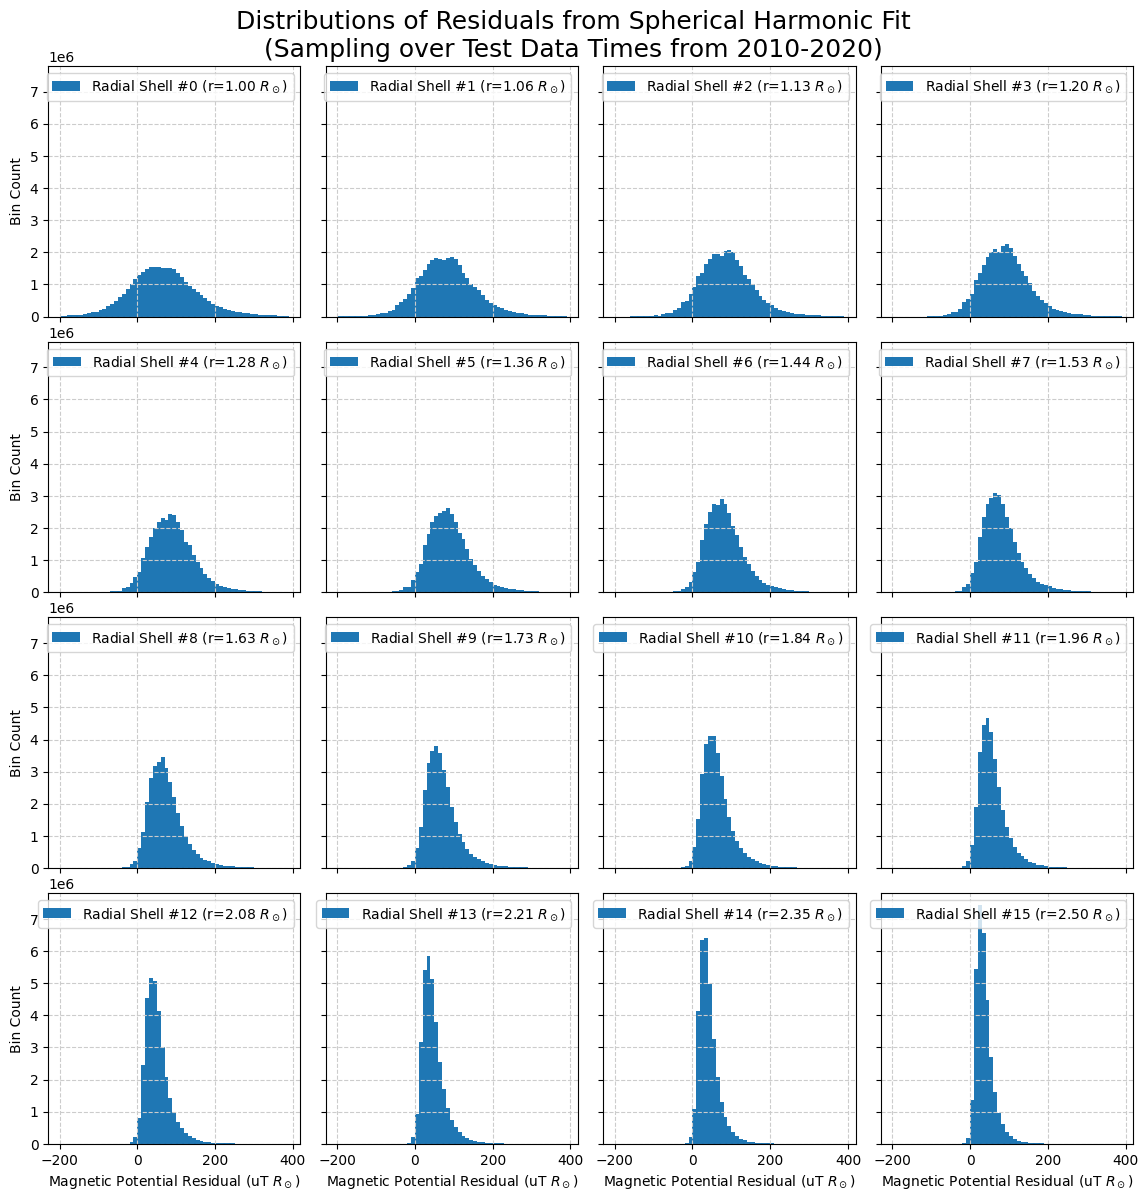

In [33]:
fig, axes = plt.subplots(4, 4, figsize=(14,14), sharex='all', sharey='all')
bins = np.arange(-200, 400, 10)

for i, ax in enumerate(axes.flatten()):
    resids, weights = read_files('../data/validation/harmonic_samples/*.hdf5', i)
    
    ax.hist(resids.flatten(), 
            weights=weights.flatten(),
            bins=bins, 
            label=f'Radial Shell #{i} (r={config.radii[i]:.2f}' +  r' $R_\odot$)')
    ax.legend()
    ax.grid(linestyle='dashed', color='#ccc')
    
for ax in axes[-1, :]: 
    ax.set_xlabel(r'Magnetic Potential Residual (uT $R_\odot$)')
for ax in axes[:, 0]: 
    ax.set_ylabel('Bin Count')
    
plt.subplots_adjust(wspace=0.1, hspace=.1)
fig.suptitle('Distributions of Residuals from Spherical Harmonic Fit\n(Sampling over Test Data Times from 2010-2020)',
             y=0.92, fontsize=18)  
fig.savefig('../plots/paper/residuals.png')